# Experiment 7: Loading, Storage and File Formats
## Problem: Analyzing Sales Data from Multiple File Formats

**Dataset:** Messy E-commerce Sales Data (103 records, 11 columns), supplied in CSV, Excel and JSON formats.

**Aim:** Load the same sales records from three file formats, inspect data quality, clean and transform the data, perform sales analysis, and create visualizations.

> The three files contain the same original records. The original dataset has missing values and one exact duplicate row. The cleaning steps below handle these issues rather than hiding them.


## 1. Import required libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import json

pd.set_option("display.max_columns", None)


## 2. Load data from CSV, Excel and JSON

In [2]:
csv_df = pd.read_csv("Sales.csv")
excel_df = pd.read_excel("Sales.xlsx")
json_df = pd.read_json("Sales.json")

print("CSV shape:", csv_df.shape)
print("Excel shape:", excel_df.shape)
print("JSON shape:", json_df.shape)

display(csv_df.head())


CSV shape: (103, 11)
Excel shape: (103, 11)
JSON shape: (103, 11)


,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
0,100,Customer_100,ORD-41285,11/22/2024,Blender,Home,3,38,Cash on Delivery,Shipped,114.00
1,101,Customer_101,ORD-35783,07-05-2025,Smartphone,Electronics,2,abd,PayPal,Processing,NaN
2,102,Customer_102,ORD-84355,12/23/2024,Tennis Racket,Sports,1,389.05,PayPal,Delivered,389.05
3,103,Customer_103,ORD-57811,3/19/2025,Science,Books,5,233.92,PayPal,Processing,1169.60
4,104,Customer_104,ORD-93614,10/20/2025,Biography,Books,1,552.51,Cash on Delivery,Processing,552.51


## 3. Explore the structure and data quality

In [3]:
print("Column names:")
print(csv_df.columns.tolist())

print("\\nData types:")
print(csv_df.dtypes)

print("\\nMissing values in each column:")
print(csv_df.isnull().sum())

print("\\nExact duplicate rows:", csv_df.duplicated().sum())

print("\\nSummary of numerical columns:")
display(csv_df.describe())


Column names:
['ID', ' Customer_Name', 'Order_ID', 'Order_Date', 'Product', ' Category', 'Quantity', 'Price', 'Payment_Method', 'Status', 'Total']
\nData types:
ID                  int64
 Customer_Name     object
Order_ID           object
Order_Date         object
Product            object
 Category          object
Quantity           object
Price              object
Payment_Method     object
Status             object
Total             float64
dtype: object
\nMissing values in each column:
ID                 0
 Customer_Name     0
Order_ID           0
Order_Date         0
Product            0
 Category          8
Quantity           5
Price              5
Payment_Method     0
Status             0
Total             14
dtype: int64
\nExact duplicate rows: 1
\nSummary of numerical columns:


,ID,Total
count,103.000000,89.000000
mean,149.640777,1232.949101
std,28.704326,2605.471455
min,100.000000,-20000.000000
25%,125.500000,582.130000
50%,149.000000,1138.760000
75%,174.500000,2153.400000
max,199.000000,4722.700000


## 4. Clean the data

In [4]:
# Work on a copy of the CSV data as the common source dataframe.
df = csv_df.copy()

# Remove extra spaces from column names and text values.
df.columns = df.columns.str.strip()
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

# Remove exact duplicate rows.
df = df.drop_duplicates()

# Convert date and numeric columns to appropriate data types.
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
for column in ["Quantity", "Price", "Total"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Fill missing category and quantity/price values with suitable values.
df["Category"] = df["Category"].fillna("Unknown")
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())
df["Price"] = df["Price"].fillna(df["Price"].median())

# Recalculate Total using Quantity * Price wherever Total is missing.
missing_total = df["Total"].isna()
df.loc[missing_total, "Total"] = (
    df.loc[missing_total, "Quantity"] * df.loc[missing_total, "Price"]
)

print("Shape after removing duplicates:", df.shape)
print("\\nMissing values after cleaning:")
print(df.isnull().sum())
display(df.head())


Shape after removing duplicates: (102, 11)
\nMissing values after cleaning:
ID                 0
Customer_Name      0
Order_ID           0
Order_Date        47
Product            0
Category           0
Quantity           0
Price              0
Payment_Method     0
Status             0
Total              0
dtype: int64


,ID,Customer_Name,Order_ID,Order_Date,Product,Category,Quantity,Price,Payment_Method,Status,Total
0,100,Customer_100,ORD-41285,2024-11-22,Blender,Home,3.0,38.00,Cash on Delivery,Shipped,114.00
1,101,Customer_101,ORD-35783,NaT,Smartphone,Electronics,2.0,538.35,PayPal,Processing,1076.70
2,102,Customer_102,ORD-84355,2024-12-23,Tennis Racket,Sports,1.0,389.05,PayPal,Delivered,389.05
3,103,Customer_103,ORD-57811,2025-03-19,Science,Books,5.0,233.92,PayPal,Processing,1169.60
4,104,Customer_104,ORD-93614,2025-10-20,Biography,Books,1.0,552.51,Cash on Delivery,Processing,552.51


## 5. Convert into a unified format and transform the data

In [5]:
# The cleaned dataframe is now the unified format for analysis.
df["Order_Year"] = df["Order_Date"].dt.year
df["Order_Month"] = df["Order_Date"].dt.month_name()
df["Order_Month_Number"] = df["Order_Date"].dt.month

print("Unified dataframe shape:", df.shape)
display(df[["Order_ID", "Order_Date", "Order_Year", "Order_Month",
            "Product", "Category", "Quantity", "Price", "Total"]].head())


Unified dataframe shape: (102, 14)


,Order_ID,Order_Date,Order_Year,Order_Month,Product,Category,Quantity,Price,Total
0,ORD-41285,2024-11-22,2024.0,November,Blender,Home,3.0,38.00,114.00
1,ORD-35783,NaT,NaN,NaN,Smartphone,Electronics,2.0,538.35,1076.70
2,ORD-84355,2024-12-23,2024.0,December,Tennis Racket,Sports,1.0,389.05,389.05
3,ORD-57811,2025-03-19,2025.0,March,Science,Books,5.0,233.92,1169.60
4,ORD-93614,2025-10-20,2025.0,October,Biography,Books,1.0,552.51,552.51


## 6. Analyze the sales data

In [6]:
total_sales = df["Total"].sum()
average_order_value = df["Total"].mean()
total_orders = df["Order_ID"].nunique()

print("Total sales:", round(total_sales, 2))
print("Average order value:", round(average_order_value, 2))
print("Number of unique orders:", total_orders)

print("\\nSales by category:")
category_sales = df.groupby("Category")["Total"].sum().sort_values(ascending=False)
display(category_sales)

print("\\nSales by payment method:")
display(df.groupby("Payment_Method")["Total"].sum().sort_values(ascending=False))

print("\\nOrder status distribution:")
display(df["Status"].value_counts())


Total sales: 134744.73
Average order value: 1321.03
Number of unique orders: 100
\nSales by category:


Category
Books          40296.460
Home           31134.050
Clothing       27582.370
Sports         21919.108
Electronics     9900.072
Unknown         8634.390
electronics     5619.590
ELECTRONICS     3708.370
sports          2691.750
electronic    -16741.430
Name: Total, dtype: float64

\nSales by payment method:


Payment_Method
Bank Transfer       46702.120
Cash on Delivery    30560.334
Credit Card         29141.892
PayPal              28340.384
Name: Total, dtype: float64

\nOrder status distribution:


Status
Returned      27
Processing    26
Shipped       23
Cancelled     15
Delivered     11
Name: count, dtype: int64

## 7. Create visualizations

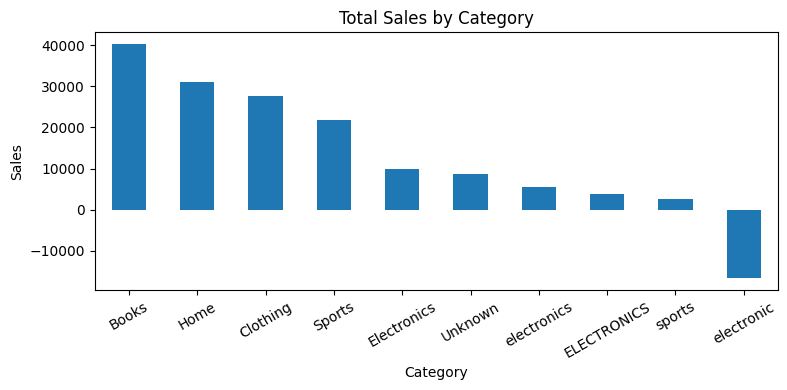

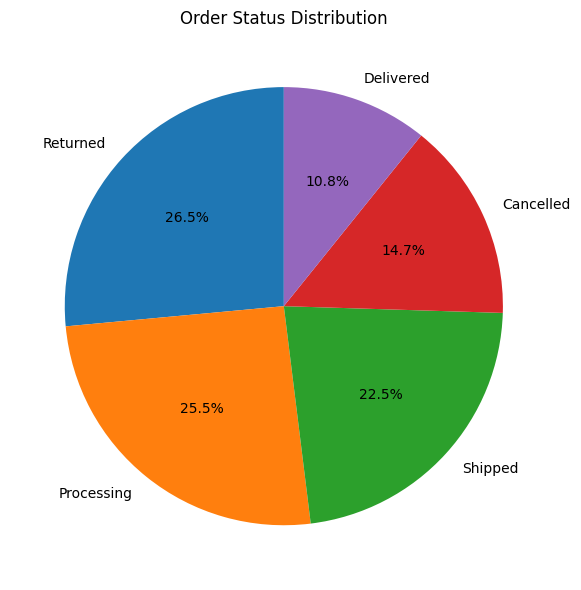

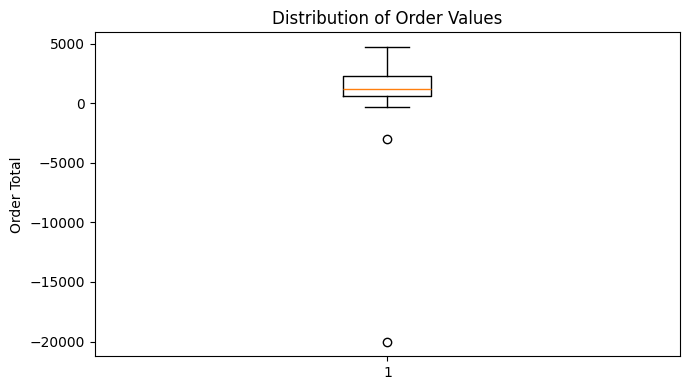

In [7]:
# Bar chart: sales by category
plt.figure(figsize=(8, 4))
category_sales.plot(kind="bar")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Pie chart: order status distribution
status_counts = df["Status"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(status_counts, labels=status_counts.index, autopct="%1.1f%%",
        startangle=90)
plt.title("Order Status Distribution")
plt.tight_layout()
plt.show()

# Box plot: order totals
plt.figure(figsize=(7, 4))
plt.boxplot(df["Total"].dropna())
plt.title("Distribution of Order Values")
plt.ylabel("Order Total")
plt.tight_layout()
plt.show()


## 8. Save the cleaned dataset

In [8]:
df.to_csv("Cleaned_Sales.csv", index=False)
df.to_excel("Cleaned_Sales.xlsx", index=False)
df.to_json("Cleaned_Sales.json", orient="records", date_format="iso", indent=2)

print("Cleaned data saved in CSV, Excel and JSON formats.")


Cleaned data saved in CSV, Excel and JSON formats.


## 9. Conclusion

Sales data was loaded successfully from CSV, Excel and JSON files. The data was explored, cleaned by removing duplicate rows and handling missing values, converted into a unified dataframe, and transformed by deriving order year and month. Sales metrics were calculated and visualized using bar, pie and box plots.

**Note:** Missing category values were labelled `Unknown`; missing quantity and price values were filled using their medians; missing totals were recalculated as Quantity × Price. These are practical cleaning choices and should be explained during the viva.
